![Banner](../../../../Images/Banner/03_spatial_analysis/03_03_banner_spatial_analysis_multidimentional.png)


# Multidimensional Principal Components Analysis

This notebook continues the multidimensional raster series and demonstrates
**ArcGIS-style Multidimensional Principal Components** with
`geolattice.spatial_analysis.multidimensional_principal_components`.


## Overview
Multidimensional Principal Components Analysis (PCA) is a statistical technique used to reduce the dimensionality of large datasets while preserving as much variance as possible. In the context of multidimensional raster data (such as climate model or remote sensing outputs), PCA helps identify key patterns and summarize the dominant modes of variability across both time and multiple variables.

Multidimensional PCA works by transforming correlated input variables (e.g., monthly surface temperature, solar radiation, heat flux, etc.) into a new set of uncorrelated variables called principal components. Each principal component represents a unique direction in the dataset's multidimensional space, ordered by the amount of original variance they capture.

The main benefits of applying PCA to multidimensional raster data are:
- **Data Reduction**: Compressing a large number of variables or time steps into a small set of informative patterns.
- **Pattern Extraction**: Revealing underlying spatial and temporal structures not immediately apparent in the raw data.
- **Noise Reduction**: Filtering out minor components that contribute less to overall variability.

In practical applications, such as climate analysis, multidimensional PCA can help distinguish between dominant climate drivers, seasonal cycles, and anomalies across regions or variables, facilitating improved visualization and further statistical modeling.


## Workflow and variables

### Workflow

1. **Load ERA forecast NetCDF** (`Data/03_spatial_analysis/NetCDF/data_2018_fc.nc`) for calendar year **2018**.
2. **Select surface / near-surface variables** and convert to analysis units.
3. **Aggregate 3-hourly fields to monthly means**.
4. **Clip to Bangladesh** (BUTM) and interpolate to a regular raster grid
   (same processing style as `03_03_01_multidimensional_data_mangement.ipynb`).
5. **Build multidimensional rasters** (one cube per variable; 12 monthly slices).
6. **Run PCA / EOF analysis**:
   - **Temporal PCA** along `time` (e.g. monthly `t2m`)
   - **Multivariate PCA** across the seven climate variables (standardized annual means)

### Variables

| Code in NetCDF | Requested name | Description | Units used here |
|---|---|---|---|
| `sshf` | sshf | Surface sensible heat flux | W m⁻² |
| `slhf` | slh | Surface latent heat flux | W m⁻² |
| `t2m` | t2m | 2 metre temperature | °C |
| `d2m` | d2m | 2 metre dewpoint temperature | °C |
| `ssr` | ssr | Surface net solar radiation | W m⁻² |
| `str` | str | Surface net thermal radiation | W m⁻² |
| `e` | e | Evaporation (ERA name; often used as ET proxy) | mm |

> **Note:** The NetCDF stores latent heat as **`slhf`** (not `slh`). Flux fields (`sshf`,
> `slhf`, `ssr`, `str`, `e`) are forecast accumulations that reset; we deaccumulate to
> rates / increments before monthly averaging.

### Dependencies
- `geolattice.spatial_analysis` (`MultidimensionalRaster`, `multidimensional_principal_components`, `raster_to_netcdf`)
- `xarray`, `geopandas`, `rasterio`, `shapely`, `scipy`, `numpy`, `pandas`, `matplotlib`


## Setup

Locate the repository root, import the PCA helpers, and create the output folder.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

import os  # environment variables for GDAL/PROJ and process paths
import ctypes  # preload libgdal into this process when needed
import warnings  # silence noisy third-party warnings in the tutorial
from pathlib import Path  # filesystem paths for locating sample data

# Jupyter kernels do not load ~/.bashrc: preload user-local GDAL so osgeo works.
_GDAL_PREFIX = Path.home() / ".local" / "share" / "gdal-prefix"  # local GDAL install prefix
_GDAL_LIBDIR = _GDAL_PREFIX / "lib"  # directory containing libgdal
_GDAL_SO = _GDAL_LIBDIR / "libgdal.so.39"  # shared library file to preload
if _GDAL_SO.is_file():  # only adjust the environment when the local build exists
    os.environ["PATH"] = f"{_GDAL_PREFIX / 'bin'}{os.pathsep}{os.environ.get('PATH', '')}"  # prepend GDAL bin
    _ld = os.environ.get("LD_LIBRARY_PATH", "")  # existing LD_LIBRARY_PATH value
    os.environ["LD_LIBRARY_PATH"] = f"{_GDAL_LIBDIR}{os.pathsep}{_ld}" if _ld else str(_GDAL_LIBDIR)  # prepend lib dir
    _gdal_data = _GDAL_PREFIX / "share" / "gdal"  # GDAL_DATA support files
    _proj_data = _GDAL_PREFIX / "share" / "proj"  # PROJ datum / grid files
    if _gdal_data.is_dir():
        os.environ.setdefault("GDAL_DATA", str(_gdal_data))  # set GDAL_DATA if not already defined
    if _proj_data.is_dir():
        os.environ.setdefault("PROJ_DATA", str(_proj_data))  # PROJ 9+ data directory
        os.environ.setdefault("PROJ_LIB", str(_proj_data))  # legacy PROJ data directory
    ctypes.CDLL(str(_GDAL_SO), mode=ctypes.RTLD_GLOBAL)  # load libgdal into this process


import numpy as np  # array ops for rasters, masks, and numeric summaries
import pandas as pd  # tabular data frames and datetime indexes
import xarray as xr  # labeled multidimensional arrays (NetCDF / Zarr)
import geopandas as gpd  # vector GeoDataFrames (points, lines, polygons)
import matplotlib.pyplot as plt  # figure and axes creation for maps and charts
import rasterio  # GeoTIFF I/O and raster metadata
from rasterio.transform import from_bounds  # build an affine transform from map bounds
from rasterio.features import geometry_mask  # rasterize polygon masks onto a grid
from scipy.interpolate import RBFInterpolator  # thin-plate spline / RBF interpolation
from pyproj import CRS  # from pyproj
from pyproj import datadir as _pyproj_datadir  # from pyproj

warnings.filterwarnings("ignore")  # keep the tutorial output readable
# Prefer Fiona over pyogrio when a custom GDAL/PROJ stack is preloaded.
os.environ.setdefault("GEOPANDAS_IO_ENGINE", "fiona")
# pyproj may not pick up PROJ_DATA from the env after GDAL preload: set explicitly.
if _proj_data.is_dir():
    _pyproj_datadir.set_data_dir(str(_proj_data))
WGS84 = CRS.from_epsg(4326)  # path or tutorial parameter

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

from geolattice.spatial_analysis import (  # import helpers from geolattice.spatial_analysis
    MultidimensionalRaster,  # cube wrapper around an xarray Dataset
    multidimensional_principal_components,  # temporal or multivariate PCA / EOF
    raster_to_netcdf,  # GeoTIFF series to NetCDF
)

NC_PATH = ROOT / "Data" / "03_spatial_analysis" / "NetCDF" / "data_2018_fc.nc"  # path or tutorial parameter
BD_SHP = (  # BD_SHP
    ROOT / "Data" / "00_shared" / "vector_data" / "Bangladesh" / "Shapefiles" / "BD_Banladesh_BUTM.shp"
)
OUT_DIR = ROOT / "Data" / "03_spatial_analysis" / "NetCDF" / "output" / "multidimensional_pca"  # path or tutorial parameter
RAS_DIR = OUT_DIR / "monthly_rasters"  # path or tutorial parameter
TAB_DIR = OUT_DIR / "tabular"  # path or tutorial parameter
PCA_DIR = OUT_DIR / "pca"  # path or tutorial parameter
for d in (OUT_DIR, RAS_DIR, TAB_DIR, PCA_DIR):  # iterate over items
    d.mkdir(parents=True, exist_ok=True)  # create the output folder if needed

YEAR = 2018  # path or tutorial parameter
RESOLUTION_M = 2000.0  # use 1000.0 to match 03_03_01 exactly (slower)
SECONDS_3H = 3 * 3600.0  # path or tutorial parameter

# NetCDF code → display alias used in filenames / plots
VARIABLES = {  # VARIABLES
    "sshf": {"alias": "sshf", "long_name": "Surface sensible heat flux", "kind": "flux_wm2"},
    "slhf": {"alias": "slh", "long_name": "Surface latent heat flux", "kind": "flux_wm2"},
    "t2m": {"alias": "t2m", "long_name": "2 metre temperature", "kind": "temp_c"},
    "d2m": {"alias": "d2m", "long_name": "2 metre dewpoint temperature", "kind": "temp_c"},
    "ssr": {"alias": "ssr", "long_name": "Surface net solar radiation", "kind": "flux_wm2"},
    "str": {"alias": "str", "long_name": "Surface net thermal radiation", "kind": "flux_wm2"},
    "e": {"alias": "e", "long_name": "Evaporation", "kind": "evap_mm"},
}

MONTH_NAMES = [  # MONTH_NAMES
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
]

print("Repo:   ", ROOT)  # confirm paths / environment
print("NetCDF: ", NC_PATH, "exists=" + str(NC_PATH.is_file()))  # confirm paths / environment
print("Boundary:", BD_SHP, "exists=" + str(BD_SHP.is_file()))  # confirm paths / environment
print("Output: ", OUT_DIR)  # confirm paths / environment
print("Grid:   ", f"{RESOLUTION_M:.0f} m")  # confirm paths / environment

try:  # confirm optional GDAL bindings resolve
    from osgeo import gdal  # from osgeo
    print("GDAL:   ", gdal.__version__, "(osgeo OK)")  # confirm paths / environment
except Exception as _exc:  # report a clear failure if osgeo is missing
    print("GDAL:    FAILED, ", _exc)  # confirm paths / environment


/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


Repo:    /home/zia207/Github/GeoLattice
NetCDF:  /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/data_2018_fc.nc exists=True
Boundary: /home/zia207/Github/GeoLattice/Data/00_shared/vector_data/Bangladesh/Shapefiles/BD_Banladesh_BUTM.shp exists=True
Output:  /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/multidimensional_pca
Grid:    2000 m
GDAL:    3.13.3 (osgeo OK)


## Helper functions

Utilities adapted from `03_03_01_multidimensional_data_mangement.ipynb`:
unit conversion / deaccumulation, monthly aggregation, Bangladesh clip,
thin-plate-spline interpolation, and multi-band GeoTIFF export.


In [2]:
def deaccumulate_forecast(da: xr.DataArray) -> xr.DataArray:
    """
    Convert forecast accumulations that reset when a new forecast cycle starts
    into per-step increments (same units as the input accumulation).
    """
    vals = np.asarray(da.values, dtype=np.float64)  # compute vals
    out = np.empty_like(vals)  # compute out
    out[0] = vals[0]  # set out[0]
    # Vectorized reset detection along time for the full 3-D cube.
    prev = vals[:-1]  # prev
    cur = vals[1:]  # cur
    # Reset when magnitude drops sharply relative to the previous step.
    reset = np.abs(cur) < (0.5 * np.abs(prev))  # compute reset
    increments = np.where(reset, cur, cur - prev)  # compute increments
    out[1:] = increments  # set out[1:]
    return xr.DataArray(out, coords=da.coords, dims=da.dims, name=da.name, attrs=dict(da.attrs))  # return the computed result


def prepare_variable(da: xr.DataArray, kind: str) -> xr.DataArray:
    """Convert a raw ERA field to analysis units."""
    if kind == "temp_c":
        out = (da - 273.15).astype("float32")  # cast to the target dtype
        out.attrs.update({"units": "degC"})
        return out  # return the computed result
    if kind == "flux_wm2":
        # Accumulated J m**-2 over each forecast step -> approximate W m**-2
        incr = deaccumulate_forecast(da)  # incr
        out = (incr / SECONDS_3H).astype("float32")  # cast to the target dtype
        out.attrs.update({"units": "W m-2"})
        return out  # return the computed result
    if kind == "evap_mm":
        # Accumulated m of water -> mm over the step
        incr = deaccumulate_forecast(da)  # incr
        out = (incr * 1000.0).astype("float32")  # cast to the target dtype
        out.attrs.update({"units": "mm"})
        return out  # return the computed result
    raise ValueError(f"Unknown kind: {kind}")  # fail with a clear error message


def to_monthly_mean(da: xr.DataArray) -> xr.DataArray:
    """Aggregate sub-daily values to calendar-month means."""
    monthly = da.resample(time="1MS").mean(skipna=True)  # temporally resample / aggregate
    # Keep only months inside the analysis year
    monthly = monthly.sel(time=slice(f"{YEAR}-01-01", f"{YEAR}-12-31"))  # select along coordinates or indices
    return monthly  # return the computed result


def monthly_to_points(monthly: xr.DataArray) -> gpd.GeoDataFrame:
    """One row per grid node; one column per month (YYYY-MM)."""
    lon2d, lat2d = np.meshgrid(monthly.longitude.values, monthly.latitude.values)  # build 2-D coordinate grids
    n_pts = lon2d.size  # n_pts
    station_id = [f"S{i:04d}" for i in range(n_pts)]  # station_id

    vals = np.moveaxis(monthly.values, 0, -1).reshape(n_pts, monthly.sizes["time"])  # compute vals
    months = pd.to_datetime(monthly.time.values).strftime("%Y-%m")  # parse timestamps
    df = pd.DataFrame(vals, columns=months)  # compute df
    df.insert(0, "station_id", station_id)
    df.insert(1, "lon", lon2d.ravel().astype("float64"))
    df.insert(2, "lat", lat2d.ravel().astype("float64"))

    geometry = gpd.points_from_xy(df["lon"], df["lat"], crs=WGS84)  # build point geometries from x/y
    return gpd.GeoDataFrame(df, geometry=geometry, crs=WGS84)  # return the computed result


def reproject_and_clip(gdf: gpd.GeoDataFrame, bd: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    proj = gdf.to_crs(bd.crs)  # reproject to the target CRS
    clipped = gpd.clip(proj, bd)  # clip points to the boundary
    return clipped.reset_index(drop=True)  # return the computed result


def make_target_grid(bd: gpd.GeoDataFrame, resolution_m: float = 2000.0):
    bounds = bd.total_bounds  # bounds
    width = int(np.ceil((bounds[2] - bounds[0]) / resolution_m))  # compute width
    height = int(np.ceil((bounds[3] - bounds[1]) / resolution_m))  # compute height
    transform = from_bounds(bounds[0], bounds[1], bounds[2], bounds[3], width, height)  # affine transform from map bounds
    xs = bounds[0] + (np.arange(width) + 0.5) * resolution_m  # compute xs
    ys = bounds[3] - (np.arange(height) + 0.5) * resolution_m  # compute ys
    X, Y = np.meshgrid(xs, ys)  # build 2-D coordinate grids
    grid_xy = np.column_stack([X.ravel(), Y.ravel()])  # stack coordinate columns
    mask = geometry_mask(  # mask
        bd.geometry, out_shape=(height, width), transform=transform, invert=True  # bd.geometry container
    )
    return width, height, transform, grid_xy, mask  # return the computed result


def tps_interpolate_band(coords_xy, values, grid_xy, height, width, mask):
    valid = np.isfinite(values)  # compute valid
    if valid.sum() < 3:
        return np.full((height, width), np.nan, dtype="float32")  # return the computed result
    rbf = RBFInterpolator(  # rbf
        coords_xy[valid], values[valid], kernel="thin_plate_spline", smoothing=0.0  # set coords_xy[valid]
    )
    pred = rbf(grid_xy).reshape(height, width).astype("float32")  # cast to the target dtype
    pred[~mask] = np.nan  # compute pred[~mask]
    return pred  # return the computed result


def write_multiband_geotiff(path: Path, bands, band_names, transform, crs):
    height, width = bands[0].shape  # height
    with rasterio.open(
        path,
        "w",
        driver="GTiff",  # driver
        height=height,  # height
        width=width,  # width
        count=len(bands),  # count
        dtype="float32",  # dtype
        crs=crs,  # crs
        transform=transform,  # transform
        nodata=np.nan,  # compute nodata
        compress="lzw",  # compress
    ) as dst:
        for i, (arr, name) in enumerate(zip(bands, band_names), start=1):  # iterate over items
            dst.write(arr, i)
            dst.set_band_description(i, name)


def stack_multiband_geotiff_to_mdr(path: Path, variable_name: str) -> MultidimensionalRaster:
    """Read a 12-band monthly GeoTIFF into MultidimensionalRaster(time, y, x)."""
    with rasterio.open(path) as src:  # open a context-managed resource
        data = src.read().astype("float32")  # (bands, y, x)
        nodata = src.nodata  # nodata
        if nodata is not None:
            data = np.where(data == nodata, np.nan, data)  # compute data
        data = np.where(np.abs(data) > 1e30, np.nan, data)  # compute data
        transform = src.transform  # transform
        height, width = src.height, src.width  # height
        xs = transform.c + (np.arange(width) + 0.5) * transform.a  # compute xs
        ys = transform.f + (np.arange(height) + 0.5) * transform.e  # compute ys
        n_bands = src.count  # n_bands
        # Prefer band descriptions like 2018-01; fall back to month starts.
        times = []  # times
        for i in range(1, n_bands + 1):  # iterate over items
            desc = src.descriptions[i - 1]  # desc
            if desc:
                times.append(np.datetime64(desc + "-01" if len(desc) == 7 else desc))
            else:
                times.append(np.datetime64(f"{YEAR}-{i:02d}-01"))

    da = xr.DataArray(  # da
        data,
        dims=("time", "y", "x"),  # dims
        coords={"time": np.array(times, dtype="datetime64[ns]"), "y": ys, "x": xs},  # coords
        name=variable_name,  # name
    )
    return MultidimensionalRaster(da)  # return the computed result


def process_variable_monthly(nc_path, varname, meta, bd, grid_cache, ras_dir, tab_dir, year=YEAR):
    """
    Full monthly pipeline for one variable:
    load -> convert -> monthly mean -> points -> clip -> CSV -> TPS -> GeoTIFF.
    """
    alias = meta["alias"]  # alias
    print(f"\n=== {varname} ({alias}): {meta['long_name']} ===")  # status / summary print
    tif_path = ras_dir / f"{alias}_{year}_monthly_{int(RESOLUTION_M)}m.tif"  # tif_path
    csv_path = tab_dir / f"{alias}_{year}_monthly_means.csv"  # csv_path

    if tif_path.is_file() and csv_path.is_file():  # only when the path exists
        print(f"  skip (exists): {tif_path.name}")  # status / summary print
        return csv_path, tif_path  # return the computed result

    ds = xr.open_dataset(nc_path)  # open the NetCDF / dataset
    raw = ds[varname].sel(time=slice(f"{year}-01-01", f"{year}-12-31"))  # select along coordinates or indices
    if raw.sizes.get("time", 0) == 0:
        ds.close()  # release the file handle
        raise ValueError(f"No timesteps for {varname} in {year}")  # fail with a clear error message
    converted = prepare_variable(raw.load(), meta["kind"])  # converted
    ds.close()  # release the file handle

    monthly = to_monthly_mean(converted)  # aggregate along time or groups
    print(f"  monthly slices: {monthly.sizes['time']}")  # status / summary print

    gdf = monthly_to_points(monthly)  # gdf
    clipped = reproject_and_clip(gdf, bd)  # reproject or clip geometries
    print(f"  points after clip: {len(clipped)}")  # status / summary print

    month_cols = [c for c in clipped.columns if c not in {"station_id", "lon", "lat", "geometry"}]  # month_cols
    wgs = clipped.to_crs(WGS84)  # reproject to the target CRS
    table = pd.DataFrame(  # table
        {
            "station_id": clipped["station_id"].values,
            "lon": wgs.geometry.x.values,
            "lat": wgs.geometry.y.values,
        }
    )
    for col in month_cols:  # iterate over items
        table[col] = clipped[col].astype("float32").values  # cast to the target dtype
    table.to_csv(csv_path, index=False)  # set table.to_csv(csv_path
    print(f"  CSV -> {csv_path.name}")  # status / summary print

    width, height, transform, grid_xy, mask = grid_cache  # width
    coords_xy = np.column_stack([clipped.geometry.x.values, clipped.geometry.y.values])  # stack coordinate columns
    bands, band_names = [], []  # bands
    for col in month_cols:  # iterate over items
        arr = tps_interpolate_band(  # arr
            coords_xy, table[col].to_numpy(), grid_xy, height, width, mask
        )
        bands.append(arr)
        band_names.append(col)
        print(f"  TPS {col}")  # status / summary print

    write_multiband_geotiff(tif_path, bands, band_names, transform, bd.crs)
    print(f"  GeoTIFF -> {tif_path.name}  ({len(bands)} bands, {width}x{height})")  # status / summary print
    return csv_path, tif_path  # return the computed result


print("Helpers ready.")  # status / summary print


Helpers ready.


## Inspect the 2018 NetCDF

Confirm dimensions, coordinates, and that all requested variables are present.


In [3]:
ds_meta = xr.open_dataset(NC_PATH)  # open the NetCDF / dataset
print(ds_meta)  # status / summary print
print("time:", ds_meta.time.values[0], "->", ds_meta.time.values[-1])  # status / summary print
print("variables:", list(ds_meta.data_vars))  # status / summary print
missing = [v for v in VARIABLES if v not in ds_meta.data_vars]  # missing
if missing:
    raise KeyError(f"Missing variables in NetCDF: {missing}")  # fail with a clear error message
for v, meta in VARIABLES.items():  # iterate over items
    units = ds_meta[v].attrs.get("units", "?")  # units
    print(f"  {v:5s} -> alias={meta['alias']:4s}  units={units}  ({meta['long_name']})")  # status / summary print
ds_meta.close()  # release the file handle


<xarray.Dataset> Size: 704MB
Dimensions:    (time: 2920, latitude: 49, longitude: 41)
Coordinates:
  * time       (time) datetime64[ns] 23kB 2018-01-01T03:00:00 ... 2019-01-01
  * latitude   (latitude) float32 196B 26.5 26.38 26.25 ... 20.75 20.62 20.5
  * longitude  (longitude) float32 164B 87.5 87.62 87.75 ... 92.25 92.38 92.5
Data variables: (12/15)
    par        (time, latitude, longitude) float64 47MB ...
    sp         (time, latitude, longitude) float64 47MB ...
    sshf       (time, latitude, longitude) float64 47MB ...
    slhf       (time, latitude, longitude) float64 47MB ...
    u10        (time, latitude, longitude) float64 47MB ...
    v10        (time, latitude, longitude) float64 47MB ...
    ...         ...
    str        (time, latitude, longitude) float64 47MB ...
    e          (time, latitude, longitude) float64 47MB ...
    mx2t       (time, latitude, longitude) float64 47MB ...
    mn2t       (time, latitude, longitude) float64 47MB ...
    ro         (time, lat

## Create monthly Bangladesh rasters

For each variable: convert units -> monthly mean -> clip to Bangladesh -> TPS
interpolation -> multi-band GeoTIFF (`12` months as bands).

Outputs:
- `Data/03_spatial_analysis/NetCDF/output/multidimensional_pca/monthly_rasters/{alias}_2018_monthly_{res}m.tif`
- matching CSV tables under `tabular/`


In [4]:
try:  # attempt optional or version-sensitive call
    bd = gpd.read_file(BD_SHP, engine="fiona")  # read the vector layer
except TypeError:  # handle the failure path
    bd = gpd.read_file(BD_SHP)  # read the vector layer
if bd.crs is None:
    raise ValueError("Bangladesh shapefile has no CRS.")  # fail with a clear error message
print("Boundary CRS:", bd.crs)  # status / summary print
print("Bounds (BUTM):", bd.total_bounds)  # status / summary print

grid_cache = make_target_grid(bd, RESOLUTION_M)  # grid_cache
width, height, transform, grid_xy, mask = grid_cache  # width
print(f"Target grid: {width} x {height} @ {RESOLUTION_M:.0f} m")  # status / summary print
print(f"Valid land pixels: {int(mask.sum())}")  # status / summary print

tif_paths = {}  # tif_paths
for varname, meta in VARIABLES.items():  # iterate over items
    csv_path, tif_path = process_variable_monthly(  # csv_path
        NC_PATH, varname, meta, bd, grid_cache, RAS_DIR, TAB_DIR, YEAR
    )
    tif_paths[meta["alias"]] = tif_path  # set tif_paths[meta["alias"]]

print("\nMonthly rasters ready:")  # status / summary print
for alias, path in tif_paths.items():  # iterate over items
    print(f"  {alias:4s} -> {path}")  # status / summary print


Boundary CRS: PROJCS["Bangladesh Universal Tranverse Mercator (BUTM_2010)",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Bounds (BUTM): [ 298521.65901686 2276992.71955721  778071.3454779  2946935.05305094]
Target grid: 240 x 335 @ 2000 m
Valid land pixels: 35143

=== sshf (sshf): Surface sensible heat flux ===
  skip (exists): sshf_2018_monthly_2000m.tif

=== slhf (slh): Surface latent heat flux ===
  skip (exists): slh_2018_monthly_2000m.tif

=== t2m (t2m): 2 metre temperature ===
  skip (exists): t2m_2018_monthly_2000m.tif

=== d2m (d2m): 2 metre dewpoint temperature ===


## Preview monthly maps

Map January and July for temperature (`t2m`) and latent heat (`slh` / `slhf`).


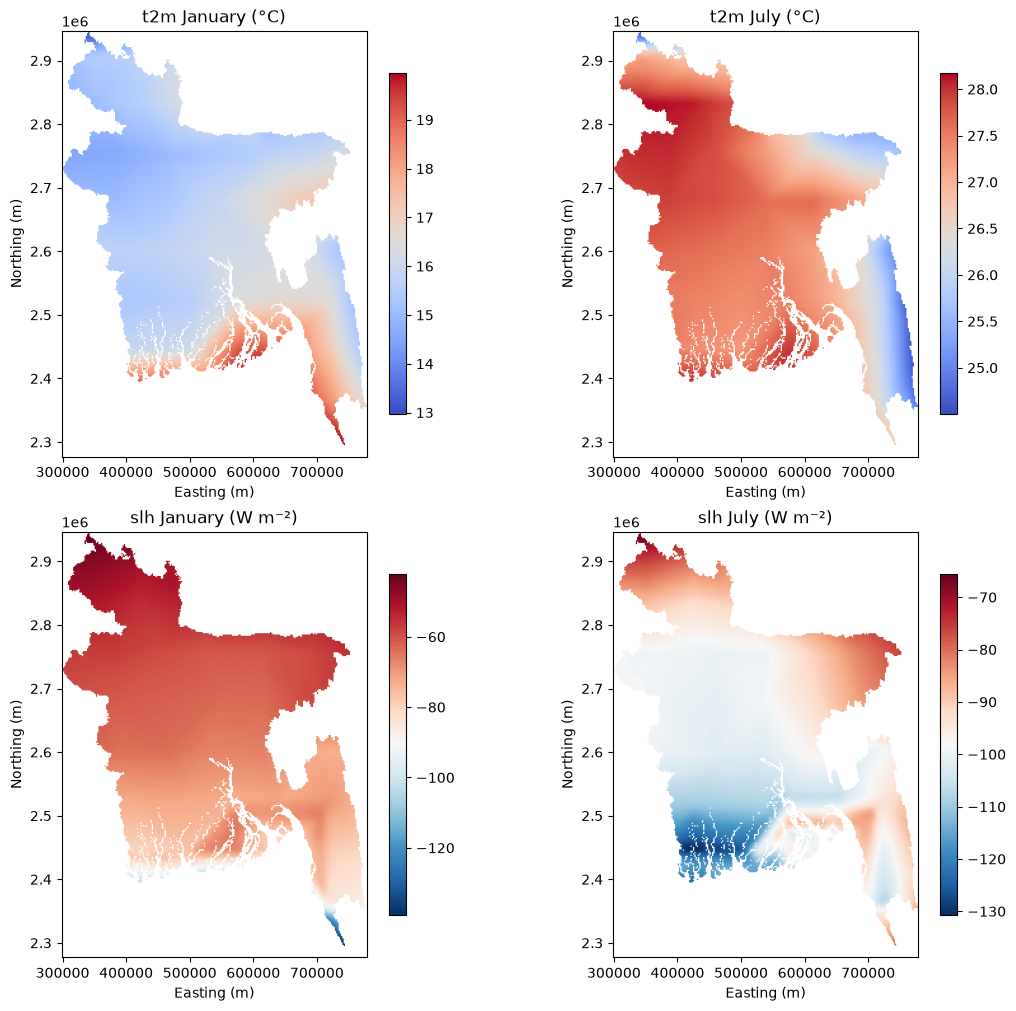

In [5]:
def read_month_band(path: Path, month_index: int):
    """month_index: 1=Jan … 12=Dec"""
    with rasterio.open(path) as src:  # open a context-managed resource
        arr = src.read(month_index).astype("float32")  # cast to the target dtype
        nodata = src.nodata  # nodata
        if nodata is not None:
            arr = np.where(arr == nodata, np.nan, arr)  # compute arr
        extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]  # extent
    return arr, extent  # return the computed result


fig, axes = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)  # create the figure and axes
previews = [  # previews
    (tif_paths["t2m"], 1, "t2m January (°C)", "coolwarm"),
    (tif_paths["t2m"], 7, "t2m July (°C)", "coolwarm"),
    (tif_paths["slh"], 1, "slh January (W m⁻²)", "RdBu_r"),
    (tif_paths["slh"], 7, "slh July (W m⁻²)", "RdBu_r"),
]
for ax, (path, month, title, cmap) in zip(axes.ravel(), previews):  # iterate over items
    arr, extent = read_month_band(path, month)  # arr
    im = ax.imshow(arr, extent=extent, origin="upper", cmap=cmap)  # show a 2-D array as an image
    ax.set_title(title)  # panel title
    ax.set_xlabel("Easting (m)")  # x-axis label
    ax.set_ylabel("Northing (m)")  # y-axis label
    fig.colorbar(im, ax=ax, shrink=0.8)  # add a colorbar
plt.show()  # render the figure


## Build multidimensional rasters

Each monthly GeoTIFF becomes a `MultidimensionalRaster` with dims `(time, y, x)`.


In [6]:
mdr_by_alias = {}  # mdr_by_alias
for alias, path in tif_paths.items():  # iterate over items
    mdr = stack_multiband_geotiff_to_mdr(path, variable_name=alias)  # build multidimensional layer
    mdr_by_alias[alias] = mdr  # set mdr_by_alias[alias]
    print(f"{alias:4s}: {mdr}")  # status / summary print

# Combined multi-variable monthly cube (for export / inspection)
combined = xr.Dataset({alias: mdr.dataset[alias] for alias, mdr in mdr_by_alias.items()})  # compute combined
combined_path = OUT_DIR / f"era_bangladesh_{YEAR}_monthly_{int(RESOLUTION_M)}m.nc"  # combined_path
combined.to_netcdf(combined_path)
print("Combined NetCDF ->", combined_path)  # status / summary print
print(combined)  # status / summary print


sshf: MultidimensionalRaster(variables=[sshf], dims={time: 12, y: 335, x: 240})
slh : MultidimensionalRaster(variables=[slh], dims={time: 12, y: 335, x: 240})
t2m : MultidimensionalRaster(variables=[t2m], dims={time: 12, y: 335, x: 240})
d2m : MultidimensionalRaster(variables=[d2m], dims={time: 12, y: 335, x: 240})
ssr : MultidimensionalRaster(variables=[ssr], dims={time: 12, y: 335, x: 240})
str : MultidimensionalRaster(variables=[str], dims={time: 12, y: 335, x: 240})
e   : MultidimensionalRaster(variables=[e], dims={time: 12, y: 335, x: 240})


Combined NetCDF -> /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/multidimensional_pca/era_bangladesh_2018_monthly_2000m.nc
<xarray.Dataset> Size: 27MB
Dimensions:  (time: 12, y: 335, x: 240)
Coordinates:
  * time     (time) datetime64[ns] 96B 2018-01-01 2018-02-01 ... 2018-12-01
  * y        (y) float64 3kB 2.946e+06 2.944e+06 ... 2.28e+06 2.278e+06
  * x        (x) float64 2kB 2.995e+05 3.015e+05 ... 7.751e+05 7.771e+05
Data variables:
    sshf     (time, y, x) float32 4MB nan nan nan nan nan ... nan nan nan nan
    slh      (time, y, x) float32 4MB nan nan nan nan nan ... nan nan nan nan
    t2m      (time, y, x) float32 4MB nan nan nan nan nan ... nan nan nan nan
    d2m      (time, y, x) float32 4MB nan nan nan nan nan ... nan nan nan nan
    ssr      (time, y, x) float32 4MB nan nan nan nan nan ... nan nan nan nan
    str      (time, y, x) float32 4MB nan nan nan nan nan ... nan nan nan nan
    e        (time, y, x) float32 4MB nan nan nan nan nan ... nan n

## Temporal PCA (EOF): monthly `t2m`

`multidimensional_principal_components` performs an SVD / EOF-style decomposition
across a dimension (here `time`). Spatial **loadings** (`pc_1`, `pc_2`, …) show
dominant spatial modes; **pc_scores** are the temporal amplitudes.


In [7]:
N_COMP = 3  # tutorial parameter
t2m_mdr = mdr_by_alias["t2m"]  # t2m_mdr

pca_t2m_mdr = multidimensional_principal_components(  # pca_t2m_mdr
    t2m_mdr,
    variable="t2m",  # variable
    dimension="time",  # dimension
    n_components=N_COMP,  # n_components
)
pca_ds = pca_t2m_mdr.dataset  # pca_ds
evr = list(pca_ds.attrs.get("explained_variance_ratio", []))  # evr
pca_nc = PCA_DIR / f"t2m_{YEAR}_temporal_pca.nc"  # pca_nc
pca_ds.to_netcdf(pca_nc)
print("Wrote", pca_nc)  # status / summary print
print("Explained variance ratio (t2m temporal PCA):")  # status / summary print
for i, r in enumerate(evr, start=1):  # iterate over items
    print(f"  PC{i}: {100 * float(r):5.2f}%")  # status / summary print
print(pca_ds)  # status / summary print


Wrote /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/multidimensional_pca/pca/t2m_2018_temporal_pca.nc
Explained variance ratio (t2m temporal PCA):
  PC1: 98.79%
  PC2:  0.99%
  PC3:  0.11%
<xarray.Dataset> Size: 2MB
Dimensions:    (y: 335, x: 240, time: 12, component: 3)
Coordinates:
  * y          (y) float64 3kB 2.946e+06 2.944e+06 ... 2.28e+06 2.278e+06
  * x          (x) float64 2kB 2.995e+05 3.015e+05 ... 7.751e+05 7.771e+05
  * time       (time) datetime64[ns] 96B 2018-01-01 2018-02-01 ... 2018-12-01
  * component  (component) int64 24B 1 2 3
Data variables:
    pc_1       (y, x) float64 643kB -5.884e-17 -3.575e-18 2.073e-18 ... 0.0 0.0
    pc_2       (y, x) float64 643kB 5.889e-16 5.623e-17 7.009e-17 ... 0.0 0.0
    pc_3       (y, x) float64 643kB -5.383e-15 4.507e-16 3.52e-18 ... 0.0 0.0
    pc_scores  (time, component) float64 288B -1.529e+03 38.35 ... 48.39 -22.37
Attributes:
    explained_variance_ratio:  [0.9879019362223562, 0.00992944394118224, 0.00

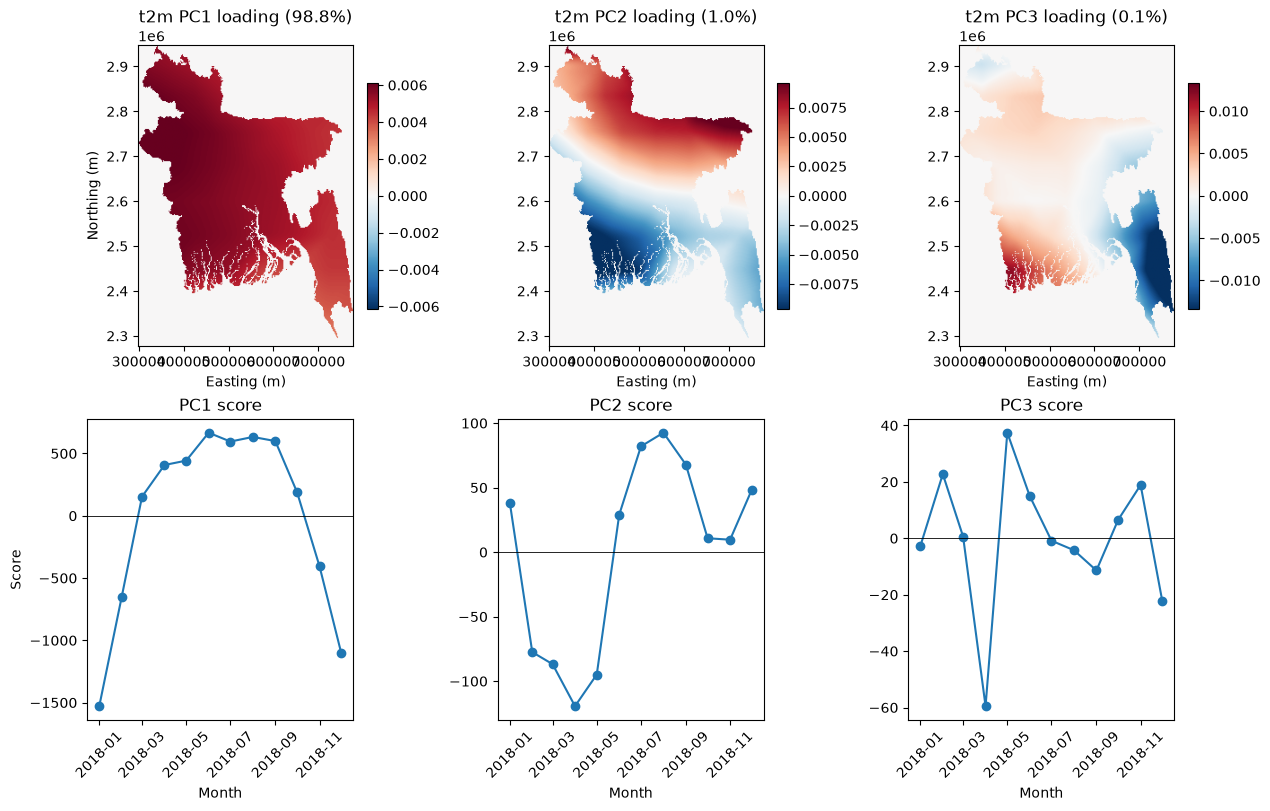

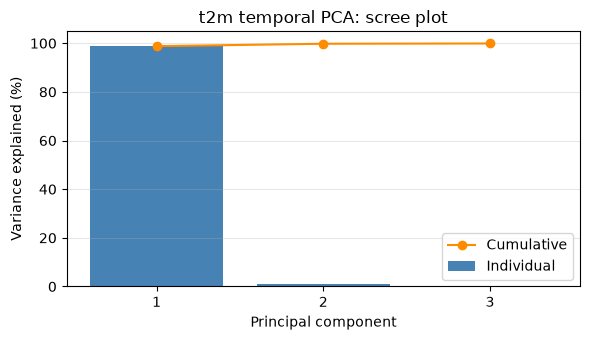

In [8]:
# Spatial loadings + temporal scores
fig, axes = plt.subplots(2, N_COMP, figsize=(4.2 * N_COMP, 8), constrained_layout=True)  # create the figure and axes

# reference extent from t2m geotiff
with rasterio.open(tif_paths["t2m"]) as src:  # open a context-managed resource
    extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]  # extent

for i in range(N_COMP):  # iterate over items
    ax = axes[0, i]  # ax
    pc = pca_ds[f"pc_{i + 1}"].values  # pc
    vmax = np.nanpercentile(np.abs(pc), 98)  # compute vmax
    im = ax.imshow(pc, extent=extent, origin="upper", cmap="RdBu_r", vmin=-vmax, vmax=vmax)  # show a 2-D array as an image
    pct = 100 * float(evr[i]) if i < len(evr) else np.nan  # compute pct
    ax.set_title(f"t2m PC{i + 1} loading ({pct:.1f}%)")  # panel title
    ax.set_xlabel("Easting (m)")  # x-axis label
    if i == 0:
        ax.set_ylabel("Northing (m)")  # y-axis label
    fig.colorbar(im, ax=ax, shrink=0.75)  # add a colorbar

scores = pca_ds["pc_scores"]  # scores
times = pd.to_datetime(scores["time"].values)  # parse timestamps
for i in range(N_COMP):  # iterate over items
    ax = axes[1, i]  # ax
    ax.plot(times, scores.values[:, i], marker="o")  # draw the map or chart
    ax.axhline(0, color="k", lw=0.6)  # set ax.axhline(0
    ax.set_title(f"PC{i + 1} score")  # panel title
    ax.set_xlabel("Month")  # x-axis label
    if i == 0:
        ax.set_ylabel("Score")  # y-axis label
    ax.tick_params(axis="x", rotation=45)  # set ax.tick_params(axis

plt.show()  # render the figure

# Scree / cumulative variance
fig, ax = plt.subplots(figsize=(6, 3.5))  # create the figure and axes
x = np.arange(1, len(evr) + 1)  # compute x
ax.bar(x, np.array(evr) * 100, color="steelblue", label="Individual")  # set ax.bar(x
ax.plot(x, np.cumsum(evr) * 100, "o-", color="darkorange", label="Cumulative")  # draw the map or chart
ax.set_xlabel("Principal component")  # x-axis label
ax.set_ylabel("Variance explained (%)")  # y-axis label
ax.set_title("t2m temporal PCA: scree plot")  # panel title
ax.set_xticks(x)  # configure tick labels
ax.legend()
ax.grid(True, axis="y", alpha=0.3)  # set ax.grid(True
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render the figure


## Multivariate PCA across climate variables

Stack the **annual mean** of each monthly raster (7 variables) as a synthetic
dimension named `variable`, standardize each field (zero mean / unit variance over
land pixels), then run `multidimensional_principal_components` across that
dimension. This highlights spatial co-variability among heat, moisture, and
radiation fields.


In [9]:
# Annual mean per variable (mean over 12 months)
annual_stack = []  # annual_stack
aliases = list(mdr_by_alias.keys())  # aliases
for alias in aliases:  # iterate over items
    annual = mdr_by_alias[alias].dataset[alias].mean(dim="time", skipna=True)  # aggregate along time or groups
    # Standardize over land pixels
    vals = annual.values.astype("float64")  # cast to the target dtype
    mu = np.nanmean(vals)  # aggregate along time or groups
    sigma = np.nanstd(vals)  # compute sigma
    if not np.isfinite(sigma) or sigma == 0:
        z = vals * np.nan  # compute z
    else:
        z = (vals - mu) / sigma  # z
    annual_stack.append(z)

arr = np.stack(annual_stack, axis=0)  # (variable, y, x)
y = mdr_by_alias[aliases[0]].dataset["y"].values  # y
x = mdr_by_alias[aliases[0]].dataset["x"].values  # x

mv_da = xr.DataArray(  # mv_da
    arr.astype("float32"),
    dims=("variable", "y", "x"),  # dims
    coords={"variable": aliases, "y": y, "x": x},  # coords
    name="climate_z",  # name
    attrs={"note": "annual-mean fields, standardized per variable"},  # attrs
)
mv_mdr = MultidimensionalRaster(mv_da)  # mv_mdr
print(mv_mdr)  # status / summary print

pca_mv_mdr = multidimensional_principal_components(  # pca_mv_mdr
    mv_mdr,
    variable="climate_z",  # variable
    dimension="variable",  # dimension
    n_components=min(N_COMP, len(aliases)),  # n_components
)
pca_mv_ds = pca_mv_mdr.dataset  # pca_mv_ds
evr_mv = list(pca_mv_ds.attrs.get("explained_variance_ratio", []))  # evr_mv
pca_mv_nc = PCA_DIR / f"multivar_{YEAR}_annual_pca.nc"  # pca_mv_nc
pca_mv_ds.to_netcdf(pca_mv_nc)
print("Wrote", pca_mv_nc)  # status / summary print
print("Explained variance ratio (multivariate annual PCA):")  # status / summary print
for i, r in enumerate(evr_mv, start=1):  # iterate over items
    print(f"  PC{i}: {100 * float(r):5.2f}%")  # status / summary print

# Variable loadings = pc_scores along the "variable" dimension
scores_mv = pca_mv_ds["pc_scores"]  # scores_mv
loadings_df = pd.DataFrame(  # loadings_df
    scores_mv.values,
    index=list(scores_mv["variable"].values),  # index
    columns=[f"PC{i}" for i in range(1, scores_mv.sizes["component"] + 1)],  # columns
)
print("\nVariable loadings (PC scores on the variable axis):")  # status / summary print
print(loadings_df.round(3))  # status / summary print
loadings_df.to_csv(PCA_DIR / f"multivar_{YEAR}_variable_loadings.csv")


MultidimensionalRaster(variables=[climate_z], dims={variable: 7, y: 335, x: 240})
Wrote /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/output/multidimensional_pca/pca/multivar_2018_annual_pca.nc
Explained variance ratio (multivariate annual PCA):
  PC1: 74.97%
  PC2: 13.69%
  PC3:  5.62%

Variable loadings (PC scores on the variable axis):
          PC1      PC2     PC3
sshf   -3.534  133.287  21.409
slh  -150.713  -22.998 -43.211
t2m   156.180  -15.139 -27.163
d2m   142.924   38.032 -13.133
ssr   179.964  -81.103  32.495
str  -174.110  -29.080  72.815
e    -150.710  -22.999 -43.212


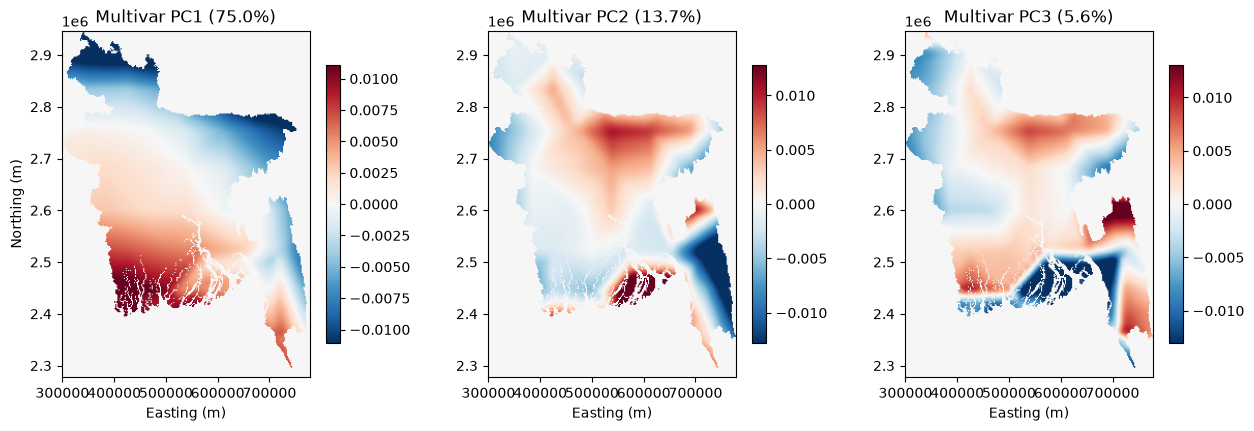

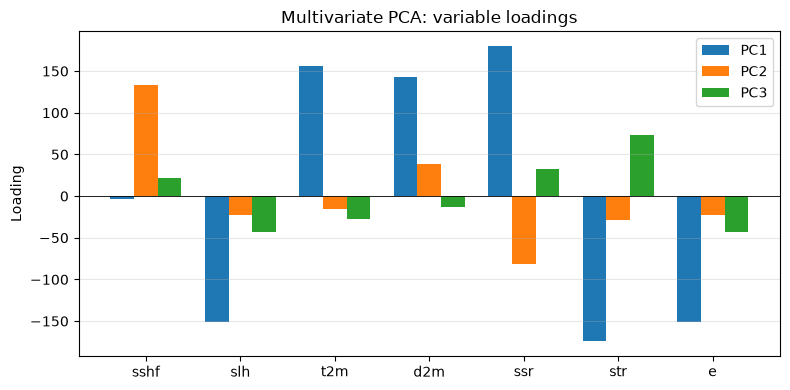

In [10]:
n_show = len(evr_mv)  # n_show
fig, axes = plt.subplots(1, n_show, figsize=(4.2 * n_show, 4.2), constrained_layout=True)  # create the figure and axes
if n_show == 1:
    axes = [axes]  # axes

for i, ax in enumerate(axes):  # iterate over items
    pc = pca_mv_ds[f"pc_{i + 1}"].values  # pc
    vmax = np.nanpercentile(np.abs(pc), 98)  # compute vmax
    im = ax.imshow(pc, extent=extent, origin="upper", cmap="RdBu_r", vmin=-vmax, vmax=vmax)  # show a 2-D array as an image
    pct = 100 * float(evr_mv[i]) if i < len(evr_mv) else np.nan  # compute pct
    ax.set_title(f"Multivar PC{i + 1} ({pct:.1f}%)")  # panel title
    ax.set_xlabel("Easting (m)")  # x-axis label
    if i == 0:
        ax.set_ylabel("Northing (m)")  # y-axis label
    fig.colorbar(im, ax=ax, shrink=0.8)  # add a colorbar
plt.show()  # render the figure

# Variable contribution bar chart
fig, ax = plt.subplots(figsize=(8, 4))  # create the figure and axes
x_pos = np.arange(len(loadings_df))  # compute x_pos
width = 0.25  # width
for i, col in enumerate(loadings_df.columns):  # iterate over items
    ax.bar(x_pos + (i - 1) * width, loadings_df[col].values, width=width, label=col)  # set ax.bar(x_pos + (i - 1) * width
ax.set_xticks(x_pos)  # configure tick labels
ax.set_xticklabels(loadings_df.index)  # style the axes
ax.axhline(0, color="k", lw=0.6)  # set ax.axhline(0
ax.set_ylabel("Loading")  # y-axis label
ax.set_title("Multivariate PCA: variable loadings")  # panel title
ax.legend()
ax.grid(True, axis="y", alpha=0.3)  # set ax.grid(True
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render the figure


## Summary

| Step | Result |
|---|---|
| Monthly rasters (7 vars x 12 months) | `multidimensional_pca/monthly_rasters/` |
| Combined monthly NetCDF | `era_bangladesh_2018_monthly_*m.nc` |
| Temporal PCA (`t2m` + all vars) | `multidimensional_pca/pca/*_temporal_pca.nc` |
| Multivariate PCA (annual z-scores) | `multidimensional_pca/pca/multivar_2018_annual_pca.nc` |

**Interpretation tips**
- Temporal PC loadings highlight regions that co-vary through the year; scores show
  which months dominate each mode (e.g. winter-summer contrast often on PC1 for `t2m`).
- Multivariate PC maps show where the joint climate fields share structure after
  standardization; variable loadings indicate which fluxes / temperatures drive each mode.

Processing geometry (BUTM clip + TPS) follows
`03_03_01_multidimensional_data_mangement.ipynb`; PCA uses
`multidimensional_principal_components` from `geolattice.spatial_analysis`.
